In [1]:
import sys
import os
sys.path.append("../src")

import pandas as pd
from data_processing import build_processed_dataset
from analysis import (
    calculate_roi,
    run_regression_analysis,
    hypothesis_test_runtime_revenue,
    hypothesis_test_franchise_revenue,
    hypothesis_test_language_revenue,
    hypothesis_test_rating_revenue,
    hypothesis_test_genre_revenue,
)
from visualization import (
    plot_average_roi_by_country,
    plot_genre_distribution,
    plot_runtime_vs_revenue,
    plot_franchise_vs_standalone_revenue,
    plot_language_revenue,
    plot_rating_vs_revenue,
    plot_genre_revenue_boxplot,
)


In [2]:
# Build the combined, cleaned dataset once (merges the 2024-2026 TMDB pull with the
# big Kaggle dataset, dedupes on id, and drops rows with zeroed-out/missing core fields).
# Re-run this cell after deleting the processed file if the raw data changes.
PROCESSED_FILE = "../data/processed/tmdb_combined_processed.xlsx"

if os.path.exists(PROCESSED_FILE):
    df = pd.read_excel(PROCESSED_FILE)
    print(f"Loaded cached processed dataset: {PROCESSED_FILE}")
else:
    df = build_processed_dataset(
        small_file="../data/raw/tmdb_movies_2024_2026.xlsx",
        big_file="../data/IMDB TMDB Movie Metadata Big Dataset (1M).csv (1).xlsx",
        output_file=PROCESSED_FILE,
    )

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns")
print(df["data_source"].value_counts())
df.head()


Loaded cached processed dataset: ../data/processed/tmdb_combined_processed.xlsx
Loaded 10,089 rows and 31 columns
data_source
big_dataset       9918
tmdb_2024_2026     171
Name: count, dtype: int64


,id,title,original_title,release_date,status,runtime_minutes,genres,overview,tagline,vote_average,...,top_10_cast,full_cast,keywords,homepage,imdb_id,poster_url,backdrop_url,adult,belongs_to_collection,data_source
0,1198553,Nidjas kitchen 2,NidÅ¾a KiÄen 2,2020-10-13 00:00:00,Released,4,"Comedy, Drama",The times have been rough on our cooking show ...,Camping comedy fun for the whole family,0.0,...,NaN,"['Erika Pluhar', 'Fritz Wotruba', 'Otto Kobale...",NaN,NaN,NaN,/dmT3uT19MtYYnBlh7ukBp8kM7qA.jpg,NaN,False,NaN,big_dataset
1,1198660,Film FodZ endgame,Film FodZ endgame,NaN,Released,764,"Action, War, Thriller, Fantasy, Crime, Documen...",highely antiapted film,a mahoney of mahoneys,0.0,...,NaN,"['Danielle Fichaud', 'Mohammad Lotfi', 'FrÃ©dÃ...",NaN,NaN,NaN,NaN,NaN,False,NaN,big_dataset
2,1197898,(Taylor's Version),(Taylor's Version),2023-10-01 00:00:00,Released,6,Comedy,Two men realise they're grappling with their l...,The Boyfriend's Guide to Taylor Swift,0.0,...,NaN,"['Ortensia Fioravanti', 'Kara Ellis']",NaN,NaN,NaN,/7URK3LX7Mxh3pISEa8MrBl6llBq.jpg,/hivWl6ftobLXL6Hz2P6JGGbFja7.jpg,False,NaN,big_dataset
3,1124489,One Minnesota,One Minnesota,2020-03-20 00:00:00,Released,70,"Horror, Romance, Mystery, History, TV Movie",Horror drama about a team-up for wealth.,"Minnesota, One.",0.0,...,NaN,"['Natalie Caron', 'Anthony Bate', 'Jean Marlow...","minnesota, saint paul, minnesota",NaN,NaN,/hDFZWcIyovOostfysHQELAb15E1.jpg,NaN,False,NaN,big_dataset
4,1124340,Spring Awakening: Filmed Live on Astral Theater,Despertar de primavera: En vivo desde el Teatr...,NaN,Released,123,Music,Spring Awakening is a coming-of-age rock music...,A different musical,0.0,...,NaN,['Unknown'],"musical, musical theatre, theatre",https://despertardeprimavera.wordpress.com/,NaN,/3b76wYnCQzehl14zBFIiwxVZoiK.jpg,NaN,False,NaN,big_dataset


In [3]:
# ROI Calculation
roi_df = calculate_roi(df)
df["ROI"] = roi_df["ROI"]
roi_df.describe()


,revenue,budget,ROI
count,1.008900e+04,1.008900e+04,10089.000000
mean,6.710818e+07,2.377788e+07,6.493302
std,1.592296e+08,3.821120e+07,122.120797
min,1.000000e+03,1.000000e+03,-0.999929
25%,1.940906e+06,2.000000e+06,-0.318098
50%,1.302276e+07,1.000000e+07,0.795455
75%,5.897865e+07,2.800000e+07,2.906251
max,3.000000e+09,4.600000e+08,9999.000000


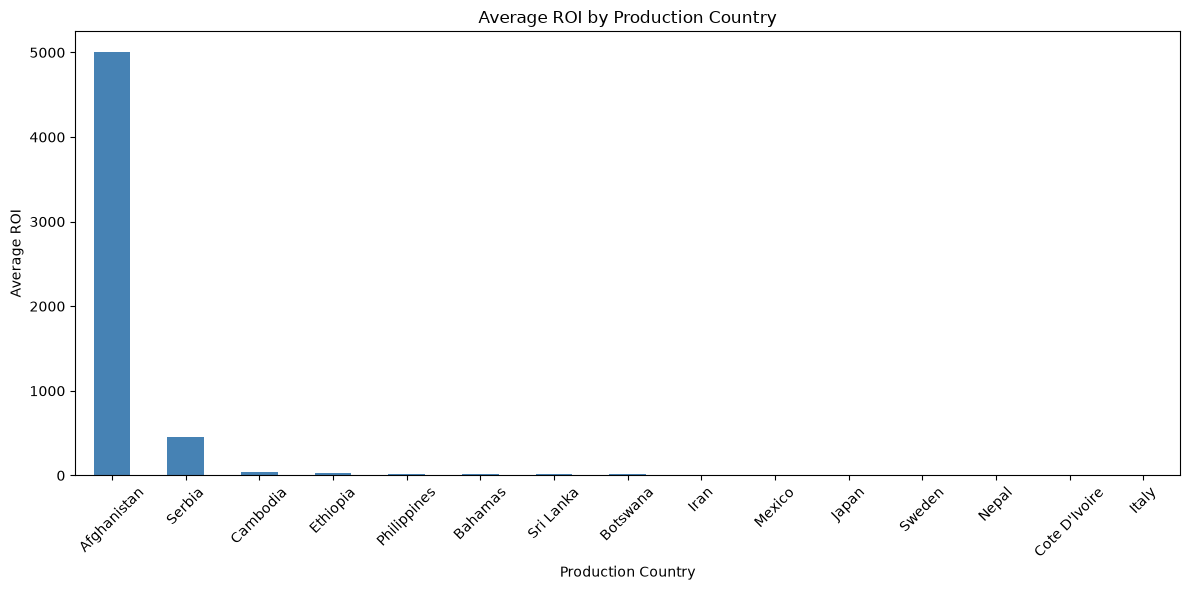

In [4]:
# Average ROI by Production Country
plot_average_roi_by_country(df)


Highest percentage genre: Drama (18.85%)
Lowest percentage genre: TV Movie (0.11%)


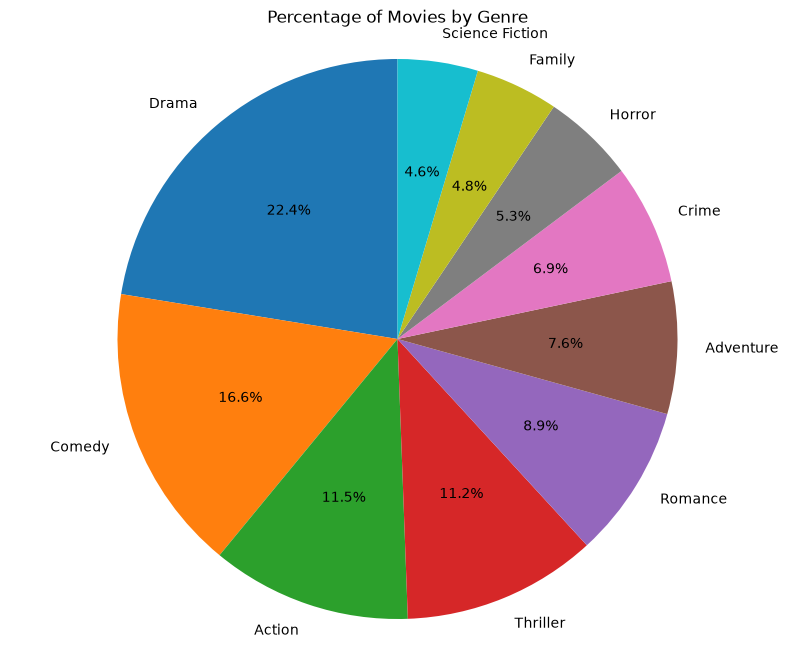

In [5]:
# Genre Distribution
genre_series = (
    df["genres"]
    .fillna("")
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
    .loc[lambda s: s != ""]
)
genre_counts = genre_series.value_counts()
genre_pct = genre_counts / genre_counts.sum() * 100

max_genre = genre_pct.idxmax()
min_genre = genre_pct.idxmin()
print(f"Highest percentage genre: {max_genre} ({genre_pct.max():.2f}%)")
print(f"Lowest percentage genre: {min_genre} ({genre_pct.min():.2f}%)")

plot_genre_distribution(df)


In [6]:
# Regression: budget -> revenue, controlling for franchise status
reg_results = run_regression_analysis(df)

print("rows_used =", reg_results["rows_used"])
print("budget_coef =", reg_results["budget_coef"])
print("franchise_coef =", reg_results["franchise_coef"])
print("franchise_p_value =", reg_results["franchise_p_value"])
print("r_squared =", reg_results["r_squared"])

import numpy as np
prem = (np.exp(reg_results["franchise_coef"]) - 1) * 100
print("approx_revenue_premium_percent =", round(prem, 4))

reg_results["summary"]


rows_used = 10089
budget_coef = 0.916424182797107
franchise_coef = 0.16080880766291727
franchise_p_value = 0.6578685650753516
r_squared = 0.6126504532197519
approx_revenue_premium_percent = 17.446


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            log_revenue   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.613
Method:                 Least Squares   F-statistic:                     7976.
Date:                Fri, 14 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:44:20   Log-Likelihood:                -19899.
No. Observations:               10089   AIC:                         3.980e+04
Df Residuals:                   10086   BIC:                         3.983e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.6455      0.114     14.421      0.000       1.422       1.869
log_budget     0.9164      0.007    126.303      0.000       0.902       0.931
franchise      0.1608      0.363      0.443      0.658      -0.551       0.873
==============================================================================
Omnibus:                     1795.522   Durbin-Watson:                   1.709
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4511.366
Skew:                          -0.986   Prob(JB):                         0.00
Kurtosis:                       5.616   Cond. No.                         330.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

{'rows_used': 10089, 'slope': np.float64(0.02880000073174459), 'intercept': np.float64(12.786737771930635), 'r': np.float64(0.301532774535989), 'p_value': np.float64(4.218319012415165e-211), 'stderr': np.float64(0.0009067290605890081)}


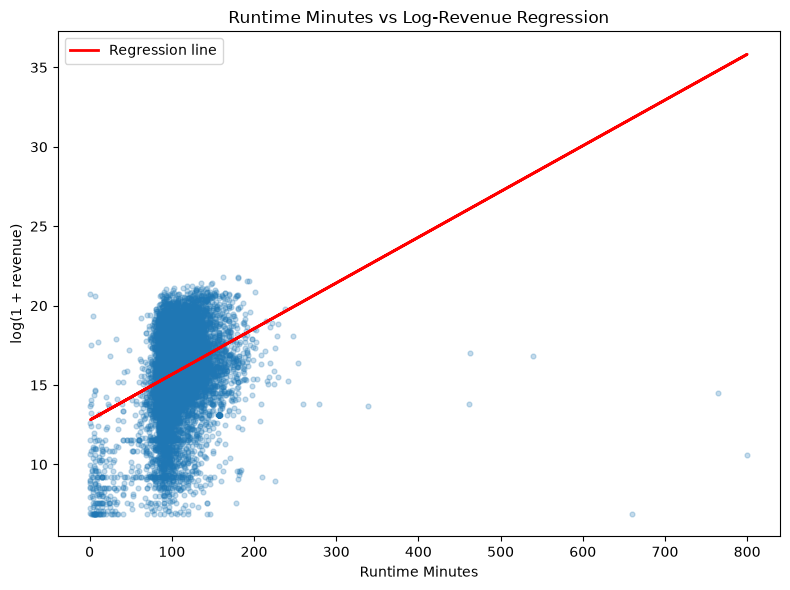

In [7]:
# Hypothesis test: does runtime relate to revenue?
runtime_results = hypothesis_test_runtime_revenue(df)
print(runtime_results)

plot_runtime_vs_revenue(df)


{'franchise_n': 23, 'standalone_n': 148, 'franchise_mean_log_revenue': np.float64(15.796037876323656), 'standalone_mean_log_revenue': np.float64(12.670088743215643), 't_stat': np.float64(3.943696992809356), 'p_value': np.float64(0.0004328268667717287)}


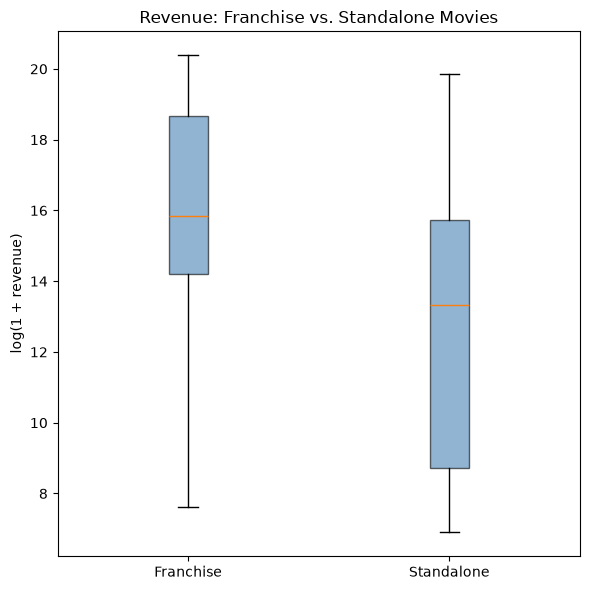

In [8]:
# Hypothesis test: does franchise membership relate to revenue?
# belongs_to_collection is only populated for the 496 movies pulled from the
# 2024-2026 source (the big dataset doesn't carry that field), so this test is
# restricted to that subset -- otherwise "standalone" would really mean "unknown".
franchise_subset = df[df["data_source"] == "tmdb_2024_2026"]
franchise_results = hypothesis_test_franchise_revenue(franchise_subset)
print(franchise_results)
plot_franchise_vs_standalone_revenue(franchise_subset)


{'english_n': 7756, 'other_n': 2333, 'english_mean_log_revenue': np.float64(16.272366741484355), 'other_mean_log_revenue': np.float64(14.618590368422307), 't_stat': np.float64(26.905170082694724), 'p_value': np.float64(6.109083837158297e-147)}


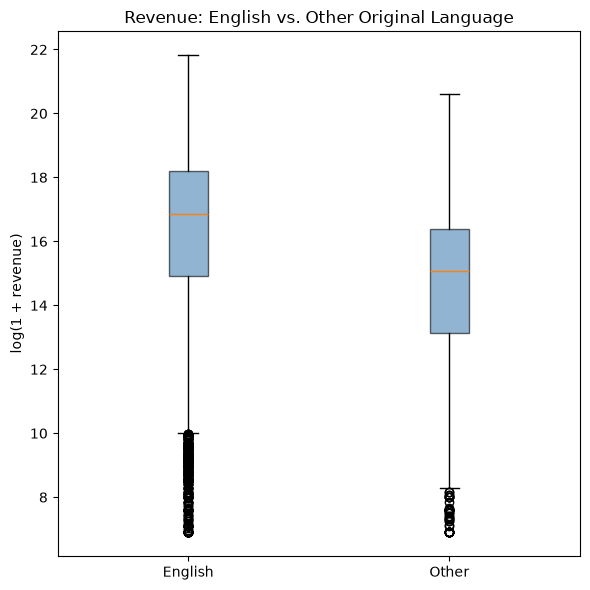

In [9]:
# Hypothesis test: does original language relate to revenue?
language_results = hypothesis_test_language_revenue(df)
print(language_results)
plot_language_revenue(df)


{'rows_used': 8461, 'r': np.float64(0.2437876231528755), 'p_value': np.float64(1.0080991594021127e-114)}


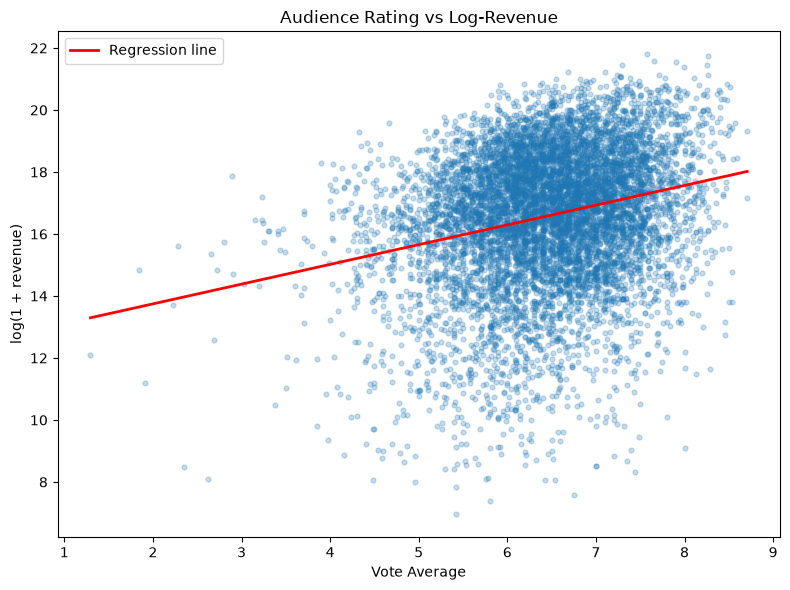

In [10]:
# Hypothesis test: does audience rating (vote_average) correlate with revenue?
rating_results = hypothesis_test_rating_revenue(df)
print(rating_results)
plot_rating_vs_revenue(df)


rows_used = 7696
genres_compared = ['Drama', 'Comedy', 'Action', 'Horror', 'Adventure', 'Crime']
f_stat = 64.9071559234937
p_value = 1.3913602881983023e-66


/Users/sarah/Desktop/filmcrowd/test/structured files/tmdb-exploratory-analysis/.venv/lib/python3.14/site-packages/scipy/integrate/_quadpack_py.py:1286: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  quad_r = quad(f, low, high, args=args, full_output=self.full_output,


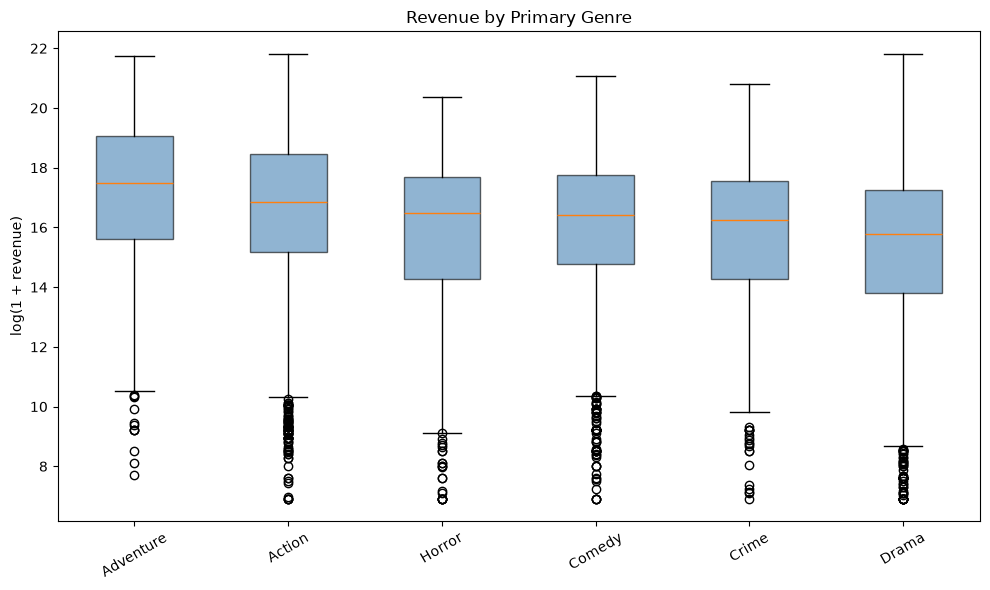

group1,group2,meandiff,p-adj,lower,upper,reject
Action,Adventure,0.7082,0.0,0.3371,1.0793,True
Action,Comedy,-0.3576,0.0009,-0.6123,-0.103,True
Action,Crime,-0.7117,0.0,-1.1152,-0.3083,True
Action,Drama,-1.1373,0.0,-1.3852,-0.8894,True
Action,Horror,-0.708,0.0,-1.0578,-0.3582,True
Adventure,Comedy,-1.0658,0.0,-1.4224,-0.7093,True
Adventure,Crime,-1.42,0.0,-1.8943,-0.9456,True
Adventure,Drama,-1.8455,0.0,-2.1973,-1.4937,True
Adventure,Horror,-1.4162,0.0,-1.8459,-0.9865,True
Comedy,Crime,-0.3541,0.1004,-0.7442,0.036,False


In [11]:
# Hypothesis test: does mean revenue differ across genres? (one-way ANOVA + Tukey HSD)
genre_results = hypothesis_test_genre_revenue(df)
print("rows_used =", genre_results["rows_used"])
print("genres_compared =", genre_results["genres_compared"])
print("f_stat =", genre_results["f_stat"])
print("p_value =", genre_results["p_value"])
plot_genre_revenue_boxplot(df)
genre_results["tukey_summary"]
